In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [38]:
# Configure matplotlib to output both SVG (vector)
%config InlineBackend.figure_formats = ['svg']

#### Building the dataset
A dictionary-based dataset will be constructed using the .dat files output from the simulation. Important things to consider for users: the algorithm relies on .dat files following a specific naming convention in `obs_K_{k}_r0_{r0}_seed_{seed}.dat`.

The initial dictionary can be accessed using the folder name key e.g.:

`dat_files_dict['fd_push_full_rod_dats']`

A specific data set can be retrieved using:

`dat_files_dict['fd_push_full_rod_dats'][(k,r0,seed)]`

At any time, use `.keys()` to identify the available data fields at any level in the dictionary. All dictionaries follow a similar organisation.

In [39]:
#### READ SIMULATION OUTPUTS AND APPEND THEM TO A DICTIONARY OF DATAFRAMES
INPUT_FOLDER = "fd_4hb_alt_dats"

import re
from pathlib import Path

def extract_parameters_from_filename(filename):
    """
    Extract K, r0, and seed from filename.

    Common patterns might be:
    - K_<value>_r0_<value>_seed_<value>.dat
    - output_K<value>_r0<value>_seed<value>.dat
    """
    pattern = r'K[_]?(\d+(?:\.\d+)?)[_]?.*r0[_]?(\d+(?:\.\d+)?)[_]?.*seed[_]?(\d+)'

    match = re.search(pattern, filename, re.IGNORECASE)
    if match:
        K = float(match.group(1))
        r0 = float(match.group(2))
        seed = int(match.group(3))
        return K, r0, seed

    return None

# Resolve input folder robustly for different notebook working directories
candidate_paths = [
    Path(INPUT_FOLDER),
    Path("oxDNA") / "tris" / INPUT_FOLDER,
    Path("tris") / INPUT_FOLDER,
]

resolved_input_folder = next((p for p in candidate_paths if p.exists() and p.is_dir()), None)
if resolved_input_folder is None:
    raise FileNotFoundError(
        f"Could not find '{INPUT_FOLDER}'. cwd={Path.cwd()} | tried={candidate_paths}"
    )

print(f"Using input folder: {resolved_input_folder.resolve()}")

# Dictionary to store data from each data group
dat_files_dict = {}

def load_dat_file(file_entry, target_dict):
    """Parse one .dat filename and append dataframe to target dictionary."""
    if not (file_entry.is_file() and file_entry.name.endswith('.dat')):
        return

    try:
        params = extract_parameters_from_filename(file_entry.name)
        if params:
            K, r0, seed = params
            data = pd.read_csv(file_entry.path, sep='\s+', header=None)
            target_dict[(K, r0, seed)] = {
                'filename': file_entry.name,
                'data': data,
                'K': K,
                'r0': r0,
                'seed': seed,
            }
        else:
            print(f"Warning: Could not extract parameters from {file_entry.name}")
    except Exception as e:
        print(f"Error reading {file_entry.path}: {e}")

# 1) Load .dat files directly in INPUT_FOLDER (this is your current layout)
root_key = resolved_input_folder.name
dat_files_dict[root_key] = {}
for file_entry in os.scandir(resolved_input_folder):
    load_dat_file(file_entry, dat_files_dict[root_key])

# 2) Also support nested subfolders (for other datasets/layouts)
for subfolder_entry in os.scandir(resolved_input_folder):
    if subfolder_entry.is_dir():
        subfolder_name = subfolder_entry.name
        dat_files_dict[subfolder_name] = {}
        for file_entry in os.scandir(subfolder_entry.path):
            load_dat_file(file_entry, dat_files_dict[subfolder_name])

# Remove empty entries
dat_files_dict = {k: v for k, v in dat_files_dict.items() if len(v) > 0}

# Summary
print(f"\n{'='*60}")
print(f"Summary: Found {len(dat_files_dict)} groups with .dat files")
print(f"{'='*60}")
for subfolder, files in dat_files_dict.items():
    print(f"{subfolder}: {len(files)} file(s)")
    if files:
        example_key = list(files.keys())[0]
        print(f"  Example access: dat_files_dict['{subfolder}'][{example_key}]")
print(f"{'='*60}")

Using input folder: C:\Users\Tristan\OneDrive - Imperial College London\Documents\YEAR_3\ReGenesis\Re-Genesis\Re-Genesis\oxDNA\tris\fd_4hb_alt_dats

Summary: Found 1 groups with .dat files
fd_4hb_alt_dats: 120 file(s)
  Example access: dat_files_dict['fd_4hb_alt_dats'][(25.0, 10.0, 1)]


In [40]:
#### TESTING OUT DICTIONARY CONTENTS AND ACCESSIBILITY
print(dat_files_dict.keys())
test = dat_files_dict['fd_4hb_alt_dats'][(25.0, 10.0, 2)]
print(test.keys())

dict_keys(['fd_4hb_alt_dats'])
dict_keys(['filename', 'data', 'K', 'r0', 'seed'])


#### Calculating steady state regions via manual cutoff

In [41]:
CUTOFF = 5e7  # adjust as needed for your simulation step scale

# Create new dictionary for steady-state filtered data
ss_dat_files_dict = {}
fallback_count = 0

# Iterate through all groups
for subfolder_name, files_dict in dat_files_dict.items():
    ss_dat_files_dict[subfolder_name] = {}

    # Iterate through all (K, r0, seed) combinations
    for (K, r0, seed), file_info in files_dict.items():
        df = file_info['data']

        # Apply cutoff filter (assuming first column is step)
        df_filtered = df[df.iloc[:, 0] >= CUTOFF].reset_index(drop=True)

        # Robust fallback: if cutoff removes everything, keep original data
        if len(df_filtered) == 0 and len(df) > 0:
            df_filtered = df.copy().reset_index(drop=True)
            fallback_count += 1

        # Store filtered (or fallback) data with same structure
        ss_dat_files_dict[subfolder_name][(K, r0, seed)] = {
            'filename': file_info['filename'],
            'data': df_filtered,
            'K': K,
            'r0': r0,
            'seed': seed
        }

# Summary
print(f"\n{'='*60}")
print("Cutoff filtering complete!")
print(f"Applied cutoff: step >= {CUTOFF}")
print(f"Processed {sum(len(files) for files in ss_dat_files_dict.values())} datasets")
if fallback_count > 0:
    print(f"Fallback used for {fallback_count} dataset(s): cutoff produced empty frames, so original data was retained.")
print(f"{'='*60}")


Cutoff filtering complete!
Applied cutoff: step >= 50000000.0
Processed 120 datasets
Fallback used for 120 dataset(s): cutoff produced empty frames, so original data was retained.


#### Computing statistics for each simulation

In [42]:
# Dictionary to store statistics for each simulation
stats_dict = {}

# Column indices (adjust based on your .dat file structure)
# Assuming columns are: [step, dist, force_mag, hbond, ...]
COL_STEP = 0
COL_DIST = 1
COL_FORCE_MAG = 2
COL_HBOND = 3

# Iterate through all subfolders
for subfolder_name, files_dict in ss_dat_files_dict.items():
    stats_dict[subfolder_name] = {}
    
    # Iterate through all (K, r0, seed) combinations
    for (K, r0, seed), file_info in files_dict.items():
        df = file_info['data']
        
        if len(df) == 0:
            print(f"Warning: Empty dataframe for {subfolder_name} (K={K}, r0={r0}, seed={seed})")
            continue
        
        # Extract columns as numpy arrays
        dist = df.iloc[:, COL_DIST].to_numpy()
        force_mag = df.iloc[:, COL_FORCE_MAG].to_numpy()
        hbond = df.iloc[:, COL_HBOND].to_numpy()
        
        # Calculate signed force: +|F| if dist > r0, -|F| if dist < r0
        signed_force = np.sign(dist - r0) * force_mag
        
        # Compute statistics
        stats_dict[subfolder_name][(K, r0, seed)] = {
            'K': K,
            'r0': r0,
            'seed': seed,
            'filename': file_info['filename'],
            
            # Signed force statistics
            'F_mean': signed_force.mean(),
            'F_std': signed_force.std(ddof=0),
            
            # Force magnitude statistics
            'force_mag_mean': force_mag.mean(),
            'force_mag_std': force_mag.std(ddof=0),
            
            # Distance statistics
            'dist_mean': dist.mean(),
            'dist_std': dist.std(ddof=0),
            
            # Hydrogen bond statistics
            'hbond_mean': hbond.mean(),
            'hbond_std': hbond.std(ddof=0),
            
            # Additional info
            'n_samples': len(df)
        }
        
        #print(f"Computed stats for {subfolder_name} (K={K}, r0={r0}, seed={seed}): {len(df)} samples")

# Summary
print(f"\n{'='*60}")
print(f"Statistics computation complete!")
print(f"Processed {sum(len(files) for files in stats_dict.values())} datasets")
print(f"{'='*60}")


Statistics computation complete!
Processed 120 datasets


In [43]:
#### SET GLOBAL RC PARAMS
plt.rcParams.update({
    "axes.linewidth": 1.5,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
    "xtick.major.size": 8,
    "ytick.major.size": 8,
    "font.size": 14,
    "axes.labelsize": 14,
})

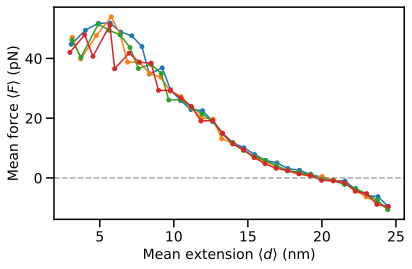

In [44]:
from collections import defaultdict
import numpy as np

# Unit conversion factors
DIST_CONVERSION = 0.8   # to nm
FORCE_CONVERSION = 48.6 # to pN

def plot_force_extension_by_seed(stats_dict, group_key=None, figsize=(6, 4), show_legend=False):
    """Plot mean force-extension curves split by (K, seed) for one data group."""
    if not stats_dict:
        print("stats_dict is empty.")
        return

    if group_key is None:
        group_key = next(iter(stats_dict.keys()))

    files_dict = stats_dict.get(group_key, {})
    if not files_dict:
        print(f"No data found for group '{group_key}'. Available: {list(stats_dict.keys())}")
        return

    grouped = defaultdict(list)
    for (K, r0, seed), stats in files_dict.items():
        grouped[(K, seed)].append((stats['dist_mean'], stats['F_mean']))

    fig, ax = plt.subplots(figsize=figsize)
    for (K, seed), points in sorted(grouped.items(), key=lambda x: (x[0][0], x[0][1])):
        points = np.array(sorted(points, key=lambda p: p[0]))
        x = DIST_CONVERSION * points[:, 0]
        y = FORCE_CONVERSION * points[:, 1]
        ax.plot(x, y, marker='o', linewidth=1.5, markersize=4, label=f"K={K}, seed={seed}")

    ax.axhline(0, color='gray', linestyle='dashed', alpha=0.7)
    ax.set_xlabel(r"Mean extension $\langle d \rangle$ (nm)")
    ax.set_ylabel(r"Mean force $\langle F \rangle$ (pN)")

    if show_legend:
        ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)

    plt.tight_layout()
    plt.show()

# Plot the current dataset
plot_force_extension_by_seed(stats_dict, group_key='fd_4hb_alt_dats', show_legend=False)

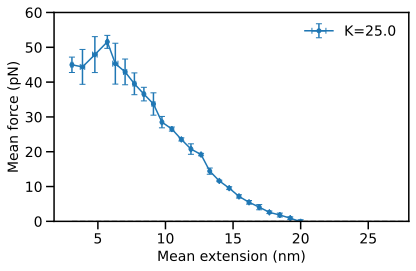

K=25.0: area under positive mean trajectory = 399.0576 pN*nm (10^-21 J) -> 57.436057 kcal/mol


In [47]:
#### Aggregate means/error bars across seeds (single dataset layout)
from collections import defaultdict
import numpy as np

AVOGADRO = 6.022e23  # molecules per mole

def aggregate_by_K_r0(stats_dict, group_key=None):
    """Aggregate mean force-extension by (K, r0) across seeds."""
    if not stats_dict:
        return {}, None

    if group_key is None:
        group_key = next(iter(stats_dict.keys()))

    files_dict = stats_dict.get(group_key, {})
    grouped = defaultdict(list)

    for (K, r0, seed), stats in files_dict.items():
        grouped[(K, r0)].append(stats)

    aggregated = defaultdict(list)
    for (K, r0), entries in grouped.items():
        dist_vals = np.array([e['dist_mean'] for e in entries])
        force_vals = np.array([e['F_mean'] for e in entries])
        ddof = 1 if len(entries) > 1 else 0

        aggregated[K].append({
            'K': K,
            'r0': r0,
            'dist_mean': dist_vals.mean(),
            'F_mean': force_vals.mean(),
            'dist_err': dist_vals.std(ddof=ddof),
            'F_err': force_vals.std(ddof=ddof),
            'n': len(entries),
        })

    for K in aggregated:
        aggregated[K] = sorted(aggregated[K], key=lambda x: x['dist_mean'])

    return dict(aggregated), group_key

def plot_aggregated_curves_by_K(stats_dict, group_key='fd_4hb_dats', figsize=(6, 4), xlim=None, ylim=None):
    aggregated_data, used_group = aggregate_by_K_r0(stats_dict, group_key=group_key)
    if not aggregated_data:
        print(f"No aggregated data available for group '{group_key}'.")
        return {}, {}

    fig, ax = plt.subplots(figsize=figsize)

    all_x = [
        DIST_CONVERSION * point['dist_mean']
        for points in aggregated_data.values()
        for point in points
    ]
    if all_x:
        xmin = min(all_x) if xlim is None or xlim[0] is None else xlim[0]
        xmax = max(all_x) if xlim is None or xlim[1] is None else xlim[1]
        ax.hlines(0, xmin=xmin, xmax=xmax, colors='gray', linestyles='dashed', alpha=0.7)

    area_by_K = {}
    for K in sorted(aggregated_data.keys()):
        points = aggregated_data[K]
        x = np.array([DIST_CONVERSION * p['dist_mean'] for p in points])
        y = np.array([FORCE_CONVERSION * p['F_mean'] for p in points])
        xerr = np.array([DIST_CONVERSION * p['dist_err'] for p in points])
        yerr = np.array([FORCE_CONVERSION * p['F_err'] for p in points])

        ax.errorbar(
            x, y, xerr=xerr, yerr=yerr,
            linestyle='-', marker='o', linewidth=1.5, markersize=4, capsize=3,
            label=f"K={K}"
        )

        area = np.trapezoid(np.maximum(y, 0.0), x) if len(x) > 1 else float('nan')
        area_by_K[K] = area

    ax.set_xlabel(r"Mean extension (nm)")
    ax.set_ylabel(r"Mean force (pN)")
    if xlim is not None:
        ax.set_xlim(*xlim)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()

    for K, area in area_by_K.items():
        kcalpermol = area * 1e-21 * AVOGADRO / 4184
        print(f"K={K}: area under positive mean trajectory = {area:.4f} pN*nm (10^-21 J) -> {kcalpermol:.6f} kcal/mol")

    return aggregated_data, area_by_K

aggregated_data, area_by_K = plot_aggregated_curves_by_K(
    stats_dict,
    group_key='fd_4hb_alt_dats',
    xlim=(None, 28),
    ylim=(0, 60),
)